In [1]:
import numpy as np
import matplotlib.pyplot as plt

MATRICOLA = 1234567890  # <-- Insert your student ID number here

def get_assignment(matricola):
    rng = np.random.default_rng(matricola)
    a = {}

    # Part 1.1: two rectangles [x1_min, x1_max] x [x2_min, x2_max]
    rects = []
    for _ in range(2):
        c = rng.uniform(-1.2, 1.2, 2)
        w = rng.uniform(0.6, 1.6, 2)
        rects.append(np.round([c[0] - w[0] / 2, c[0] + w[0] / 2, c[1] - w[1] / 2, c[1] + w[1] / 2], 2).tolist())
    a["rectangles"] = rects

    # Part 1.2: activation function and regularization
    a["elu_c"] = round(float(rng.uniform(0.5, 1.5)), 2)
    a["weight_decay"] = float(10.0 ** rng.integers(-4, -1))

    # Part 2.1: quadratic function
    n = 5
    mu = round(float(rng.uniform(0.5, 2.0)), 2)
    kappa = int(rng.integers(10, 100))
    eigs = np.sort(np.concatenate([[mu, mu * kappa], mu * kappa ** rng.uniform(0, 1, n - 2)]))
    Q, _ = np.linalg.qr(rng.normal(0, 1, (n, n)))
    a["A"] = Q @ np.diag(eigs) @ Q.T
    a["b"] = np.round(rng.normal(0, 1, n), 2)

    # Part 2.2: Rosenbrock-like function
    a["rosenbrock_a"] = int(rng.integers(5, 100))

    # Part 3: dataset and model
    a["classes"] = sorted(rng.choice(10, 4, replace=False).tolist())
    a["label_noise"] = float(rng.choice([0.1, 0.2, 0.3]))
    a["hidden"] = [int(rng.choice([64, 128, 256])), int(rng.choice([32, 64, 128]))]
    a["optimizer"] = str(rng.choice(["AdaGrad", "Nesterov", "AMSGrad"]))
    return a

assignment = get_assignment(MATRICOLA)
for key, value in assignment.items():
    if key != "A":
        print(f"{key:15s}: {value}")
print("A =\n", np.round(assignment["A"], 3))

rectangles     : [[-0.1, 1.1, -1.59, -0.21], [-0.06, 1.46, -1.74, -0.58]]
elu_c          : 1.06
weight_decay   : 0.001
b              : [ 0.76  0.54  0.23  0.01 -0.48]
rosenbrock_a   : 87
classes        : [1, 3, 7, 9]
label_noise    : 0.1
hidden         : [256, 128]
optimizer      : AdaGrad
A =
 [[ 14.43    4.33   -3.644  -1.186   1.606]
 [  4.33   16.95    5.316   6.901   9.388]
 [ -3.644   5.316  41.741 -22.71  -13.76 ]
 [ -1.186   6.901 -22.71   28.958  12.055]
 [  1.606   9.388 -13.76   12.055  19.8  ]]


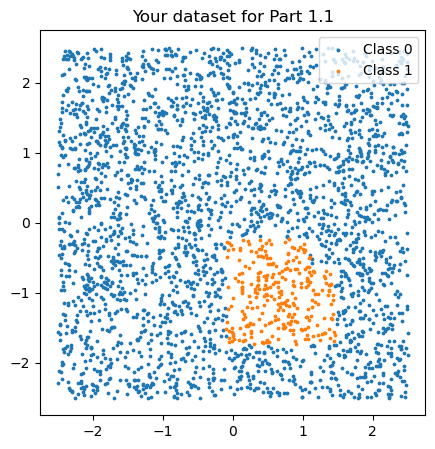

In [2]:
def make_rectangles_dataset(rects, N=3000, seed=0):
    rng = np.random.default_rng(seed)
    X = rng.uniform(-2.5, 2.5, (N, 2))
    y = np.zeros(N, dtype=int)
    for r in rects:
        y |= ((X[:, 0] >= r[0]) & (X[:, 0] <= r[1]) & (X[:, 1] >= r[2]) & (X[:, 1] <= r[3])).astype(int)
    return X, y

X_rect, y_rect = make_rectangles_dataset(assignment["rectangles"])

plt.figure(figsize=(5, 5))
plt.scatter(X_rect[y_rect == 0, 0], X_rect[y_rect == 0, 1], s=3, label="Class 0")
plt.scatter(X_rect[y_rect == 1, 0], X_rect[y_rect == 1, 1], s=3, label="Class 1")
plt.gca().set_aspect("equal")
plt.legend()
plt.title("Your dataset for Part 1.1")
plt.show()

In [3]:
# Your code here

In [4]:
# Your code here

In [5]:
# Your code here

In [6]:
# Your code here

In [7]:
# Your code here

In [8]:
import os
import gzip
import urllib.request

def load_fashion_mnist_subset(classes, label_noise, seed=0, data_dir="../Optimization/data/fashion_mnist"):
    url = "https://github.com/zalandoresearch/fashion-mnist/raw/master/data/fashion/"
    files = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
             "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
    os.makedirs(data_dir, exist_ok=True)
    data = []
    for i, filename in enumerate(files):
        path = os.path.join(data_dir, filename)
        if not os.path.exists(path):
            urllib.request.urlretrieve(url + filename, path)
        with gzip.open(path, "rb") as f:
            offset = 16 if i % 2 == 0 else 8
            data.append(np.frombuffer(f.read(), dtype=np.uint8, offset=offset))
    X_train, y_train, X_test, y_test = data
    X_train = X_train.reshape(-1, 784).astype(np.float64) / 255.0
    X_test = X_test.reshape(-1, 784).astype(np.float64) / 255.0

    # Keep only the selected classes, and map them to 0, ..., len(classes) - 1
    def select(X, y):
        mask = np.isin(y, classes)
        return X[mask], np.searchsorted(classes, y[mask])
    X_train, y_train = select(X_train, y_train.astype(int))
    X_test, y_test = select(X_test, y_test.astype(int))

    # Train / validation split
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X_train))
    val_idx, train_idx = idx[:4000], idx[4000:]
    X_val, y_val = X_train[val_idx], y_train[val_idx]
    X_train, y_train = X_train[train_idx], y_train[train_idx].copy()

    # Label noise (only on the training set)
    K = len(classes)
    noisy = rng.random(len(y_train)) < label_noise
    y_train[noisy] = (y_train[noisy] + rng.integers(1, K, noisy.sum())) % K
    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = load_fashion_mnist_subset(
    assignment["classes"], assignment["label_noise"])
print(f"Train: {X_train.shape}, validation: {X_val.shape}, test: {X_test.shape}")

Train: (20000, 784), validation: (4000, 784), test: (4000, 784)


In [9]:
# Your code here